# A1_Q3: Linear Regression with Regularization

### Given code template:

* ```python
    def run_poly_regression(X_train, y_train, X_val, y_val, X_test, y_test, degree=1, regularizer=None, reg_strength=0.0):
        """
        Fit a polynomial regression model with optimal regularization.

        Parameters:
            degreee (int): Degree of the polynomial to fit
            regularizer (str or None): 'l1', 'l2', or None
            reg_strength (float): Regularization coefficient (alpha)

        Returns: dict with train, val, and test MSEs, and learned coefficients
        """
    ```

### Tasks to perform:

* Using `student_data.csv` from Assignment 1 for dataset
* Task is to predict `GPA` using student features
* Need to use a validation set to select the hyperparameters
* For three setups - no regularization, L1 and L2 regularization, repeat the below steps:
    - Fit polynomial regression models across degrees 1 to 6.
    - Plot polynomial degree vs MSE (on train and validation sets). Describe the trend
    you observe as degree increases.
    - For each degree, use val MSE to choose the best regularization strength.
    - Plot regularization strength (log scale) vs val MSE for best degree.
* Comment on performance improvement (if any) from regularization. Which overall
experimental setup (degree, regularizer) yielded the best test performance?
* For the best setup using L1 regularization, which features had non-zero weights?
List the most important predictors for GPA. Repeat the same with L2 regularization.
Comment on the differences.
* You are allowed to use sklearn.linear model.LinearRegression

### Step 1: Data Preparation

In [2]:
import pandas as pd
import hashlib
from sklearn.model_selection import train_test_split

class DataPreprocessor:
    """
    A class to preprocess student data

    It encapsulated loading, feature/target separation, encoding,
    and splitting the data into training, validation, and test sets.
    """
    def __init__(self, filepath, target_column, username):
        self.filepath = filepath
        self.target_column = target_column
        self.username = username
        self.seed = self._generate_seed()

        # Initialize attributes to store data at various stages
        self.df = None
        self.X = None
        self.Y = None
        self.X_encoded = None
        self.X_train, self.y_train = None, None
        self.X_val, self.y_val = None, None
        self.X_test, self.y_test = None, None

    def _generate_seed(self):
        """Generates a consistent random seed from a username"""
        return int(hashlib.sha256(self.username.encode()).hexdigest(), 16) % (2**32)
    
    def load_data(self):
        """Loads data from the CSV file."""
        self.df = pd.read_csv(self.filepath)
        print(self.df.head())
        return self
    
    def separate_features_target(self):
        """Separates the Dataframe into features (X) and target (y)"""
        if self.df is None:
            raise ValueError("Data is not loaded. Please call load_data() first.")
        self.X = self.df.drop(columns=self.target_column)
        self.y = self.df[self.target_column]
        return self
    
    def encode_categorical_features(self, columns_to_encode):
        """Applies one-hot encoding to specified categorical columns."""
        if self.X is None:
            raise ValueError("Features (X) not created. Please call separate_features_target() first.")
        self.X_encoded = pd.get_dummies(self.X, columns=columns_to_encode, drop_first=True)
        print(self.X_encoded.head())
        return self
    
    def encode_ordinal_features(self, columns_to_encode, order):
        """Encodes one or more ordinal features based on a specified order."""
        if self.X_encoded is None:
            raise ValueError("Encoded features (X_encoded) not created. Please call encode_categorical_features() first.")
        
        # Loop through each column specified in the list
        for col in columns_to_encode:
            # Apply the ordinal encoding to the correct DataFrame (self.X_encoded)
            self.X_encoded[col] = pd.Categorical(self.X_encoded[col], categories=order, ordered=True).codes
            
        print("After Ordinal Encoding:")
        print(self.X_encoded.head())
        return self
    
    def split_data(self, test_size=0.2, val_size=0.5):
        """Splits the data into training, validation, and test sets."""
        if self.X_encoded is None:
            raise ValueError("Data not encoded. Please call encode_categorical_features() first.")
        
        # Split into training (80%) and temporary (20%) sets
        self.X_train, X_temp, self.y_train, y_temp = train_test_split(
            self.X_encoded, self.y, test_size=test_size, random_state=self.seed
        )

        # Split the temporary set into validation (10%) and test (10%) sets
        self.X_val, self.X_test, self.y_val, self.y_test = train_test_split(
            X_temp, y_temp, test_size=val_size, random_state=self.seed
        )
        print(f"Training set size: {len(self.X_train)}, {len(self.y_train)} samples")
        print(f"Validation set size: {len(self.X_val)}, {len(self.y_val)} samples")
        print(f"Test set size: {len(self.X_test)}, {len(self.y_test)} samples")
        return self
        
    def get_split_data(self):
        """Returns the final split datasets."""
        return self.X_train, self.X_val, self.X_test, self.y_train, self.y_val, self.y_test
    
# Define parameters
FILEPATH = 'student_data.csv'
TARGET = 'GPA'
USERNAME = 'bhogadi.likhit'
SEED = 'manitej.sriram'
# SEED = 'tony.stark'
# CATEGORICAL_COLS = ['Gender', 'Major', 'Program']
CATEGORICAL_COLS = ['Gender', 'Program']
ORDINAL_COLS = ['Major']
ORDINAL_ORDER = ['B.Tech', 'MS', 'PhD']

# 1. Instantiate the preprocessor
preprocessor = DataPreprocessor(filepath=FILEPATH, target_column=TARGET, username=SEED)

# 2. Run the preprocessing steps in a chain
(preprocessor.load_data()
             .separate_features_target()
             .encode_categorical_features(columns_to_encode=CATEGORICAL_COLS)
             .encode_ordinal_features(columns_to_encode=ORDINAL_COLS, order=ORDINAL_ORDER)
             .split_data())

# 3. Retrieve the final datasets
X_train, X_val, X_test, y_train, y_val, y_test = preprocessor.get_split_data()

   Gender   Major Program   GPA
0    Male      MS     CSE  7.59
1    Male  B.Tech     CHD  5.19
2    Male      MS     ECE  8.05
3    Male      MS     ECE  7.35
4  Female      MS     CND  7.87
    Major  Gender_Male  Gender_Other  Program_CND  Program_CSE  Program_ECE
0      MS         True         False        False         True        False
1  B.Tech         True         False        False        False        False
2      MS         True         False        False        False         True
3      MS         True         False        False        False         True
4      MS        False         False         True        False        False
After Ordinal Encoding:
   Major  Gender_Male  Gender_Other  Program_CND  Program_CSE  Program_ECE
0      1         True         False        False         True        False
1      0         True         False        False        False        False
2      1         True         False        False        False         True
3      1         True       

### Step 2: Build the Regression Pipeline

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Lasso, Ridge

def build_regression_pipeline(degree=1, regularizer=None, reg_strength=0.01):
    """
    Creates a machine learning pipeline for polynomial regression with optional regularization.
    Parameters:
    - degree: Degree of the polynomial features.
    - regularizer: Type of regularization ('l1' for Lasso, 'l2' for Ridge, None for no regularization).
    - reg_strength: Regularization strength (alpha).
    Returns:
    - A sklearn Pipeline object.
    """
    # A list of (name, transformer/estimator) tuples
    steps = [
        ('poly_features', PolynomialFeatures(degree=degree, include_bias=False)),  # First step: polynomial features
        ('scaler', StandardScaler()),         # Second step: a transformer
    ]

    if regularizer == 'l1':
        steps.append(('regressor', Lasso(alpha=reg_strength)))
    elif regularizer == 'l2':
        steps.append(('regressor', Ridge(alpha=reg_strength)))
    elif regularizer is None:
        steps.append(('regressor', LinearRegression()))
    else:
        raise ValueError("regularizer must be 'l1', 'l2', or None")

    # Create the pipeline object
    pipeline = Pipeline(steps)

    return pipeline

### Step 3: The Experiment Loop

In [4]:
import numpy as np

def run_poly_regression(X_train, y_train, X_val, y_val, X_test, y_test):
    """
    Trains polynomial regression models with varying degrees and regularization,
    evaluates them, and stores the results.
    Parameters:
    - X_train, y_train: Training data
    - X_val, y_val: Validation data
    - X_test, y_test: Test data
    Returns:
    - A list of dictionaries containing results for each configuration.
    """
    results = [] # To store results for each configuration
    strengths_results = [] # To store all strengths for each degree and regularizer

    for regularizer in ['None', 'l1', 'l2']:
        for degree in range(1, 7): # Degrees 1 to 6
            
            # If using regularization, you need to find the best strength
            if regularizer in ['l1', 'l2']:
                best_val_mse = float('inf')
                best_strength = None
                
                # A good range for regularization strength on a log scale
                strengths_to_try = np.logspace(-4, 2, 20)
                
                for strength in strengths_to_try:
                    # 1. Create your pipeline (PolynomialFeatures, StandardScaler, Model)
                    #    - Set the model to Lasso(alpha=strength) or Ridge(alpha=strength)
                    pipeline = build_regression_pipeline(degree=degree, regularizer=regularizer, reg_strength=strength)

                    # 2. Fit the pipeline on the TRAINING data
                    pipeline.fit(X_train, y_train)

                    # 3. Calculate MSE on the VALIDATION data
                    y_val_pred = pipeline.predict(X_val)
                    current_val_mse = np.mean((y_val - y_val_pred) ** 2)

                    # Store the strength and corresponding validation MSE
                    strengths_results.append({
                        'regularizer': regularizer,
                        'degree': degree,
                        'strength': strength,
                        'val_mse': current_val_mse
                    })
                    
                    # If this strength is the best so far, save it
                    if current_val_mse < best_val_mse:
                        best_val_mse = current_val_mse
                        best_strength = strength
                
                # Now you have the best strength for this degree.
                # Re-train a model with this best strength to get the final
                # train/val/test scores for this degree.
                best_strength_pipeline = build_regression_pipeline(degree=degree, regularizer=regularizer, reg_strength=best_strength)
                best_strength_pipeline.fit(X_train, y_train)

                y_train_pred = best_strength_pipeline.predict(X_train)
                y_val_pred = best_strength_pipeline.predict(X_val)
                y_test_pred = best_strength_pipeline.predict(X_test)
                train_mse = np.mean((y_train - y_train_pred) ** 2)
                val_mse = np.mean((y_val - y_val_pred) ** 2)
                test_mse = np.mean((y_test - y_test_pred) ** 2)

            else: # No regularization
                # 1. Create your pipeline (PolynomialFeatures, StandardScaler, LinearRegression)
                pipeline = build_regression_pipeline(degree=degree, regularizer=None)

                # 2. Fit on TRAINING data
                pipeline.fit(X_train, y_train)
                # 3. Calculate and store MSE for TRAIN, VALIDATION, and TEST sets.
                y_train_pred = pipeline.predict(X_train)
                y_val_pred = pipeline.predict(X_val)
                y_test_pred = pipeline.predict(X_test)
                train_mse = np.mean((y_train - y_train_pred) ** 2)
                val_mse = np.mean((y_val - y_val_pred) ** 2)
                test_mse = np.mean((y_test - y_test_pred) ** 2)
            
            # Store all results (degree, best_strength, train_mse, val_mse, test_mse)
            # for later plotting and analysis.
            results.append({
                'regularizer': regularizer,
                'degree': degree,
                'best_strength': best_strength if regularizer in ['l1', 'l2'] else None,
                'train_mse': train_mse,
                'val_mse': val_mse,
                'test_mse': test_mse
            })

    return results, strengths_results

In [5]:
# Run the polynomial regression experiments
results, strengths_results = run_poly_regression(X_train, y_train, X_val, y_val, X_test, y_test)

/home/likhitbhogadi/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.217e+00, tolerance: 8.668e-01
  model = cd_fast.enet_coordinate_descent(
/home/likhitbhogadi/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.512e+00, tolerance: 8.668e-01
  model = cd_fast.enet_coordinate_descent(
/home/likhitbhogadi/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasi

### Step 4: Visualization and Analysis

#### Plots for polynomial degree vs MSE (on train and validation sets)

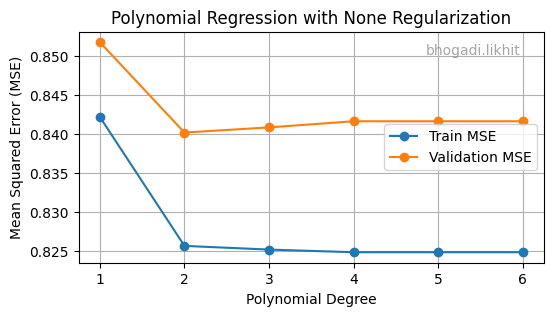

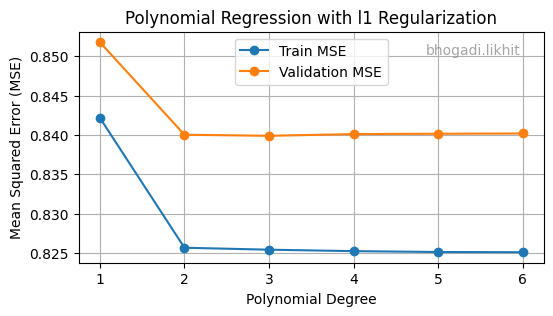

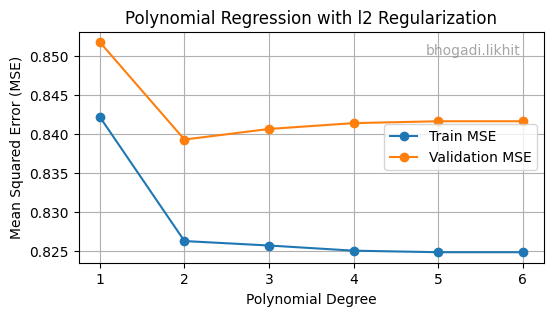

   regularizer  degree  best_strength  train_mse   val_mse
0         None       1            NaN   0.842172  0.851788
1         None       2            NaN   0.825613  0.840180
2         None       3            NaN   0.825139  0.840840
3         None       4            NaN   0.824799  0.841630
4         None       5            NaN   0.824799  0.841630
5         None       6            NaN   0.824799  0.841630
6           l1       1       0.000100   0.842172  0.851799
7           l1       2       0.000428   0.825658  0.840031
8           l1       3       0.000886   0.825409  0.839894
9           l1       4       0.000886   0.825224  0.840115
10          l1       5       0.000886   0.825115  0.840154
11          l1       6       0.000886   0.825087  0.840193
12          l2       1       0.000100   0.842172  0.851788
13          l2       2      48.329302   0.826235  0.839277
14          l2       3     100.000000   0.825661  0.840640
15          l2       4      48.329302   0.824998  0.8413

In [6]:
# Plot Degree vs MSE for each regularization type

import matplotlib.pyplot as plt

def add_username_to_plot(username):
    """Helper method to add the username to a plot."""
    plt.text(
        0.95, 0.95, username,
        ha='right', va='top',
        transform=plt.gca().transAxes,
        fontsize=10, color='gray', alpha=0.7
    )

def plot_results(results):
    """
    Plots Degree vs MSE for training, validation, and test sets for each regularization type.
    Parameters:
    - results: List of dictionaries containing results for each configuration.
    """
    # Convert results to DataFrame for easier plotting
    results_df = pd.DataFrame(results)

    for regularizer in ['None', 'l1', 'l2']:
        subset = results_df[results_df['regularizer'] == regularizer]
        
        plt.figure(figsize=(6, 3))
        plt.plot(subset['degree'], subset['train_mse'], marker='o', label='Train MSE')
        plt.plot(subset['degree'], subset['val_mse'], marker='o', label='Validation MSE')
        
        plt.xlabel('Polynomial Degree')
        plt.ylabel('Mean Squared Error (MSE)')
        plt.title(f'Polynomial Regression with {regularizer} Regularization')
        plt.xticks(subset['degree'])
        plt.legend()
        plt.grid(True)
        add_username_to_plot(USERNAME)
        # 1. Find the maximum MSE value in the current subset's data
        max_mse = max(subset['train_mse'].max(), subset['val_mse'].max())
        
        # 2. Set the top of the y-axis to be 20% higher than the max value
        #    You can change 1.2 to 1.1 (10%), 1.5 (50%), etc.
        top_limit = max_mse * 1.2
        
        # 3. Set both the bottom and top limits in one command
        # plt.ylim(bottom=0, top=top_limit)

        plt.show()
        
# Plot the results
plot_results(results)
# Print the results in a tabular format for clarity
results_df = pd.DataFrame(results).drop(columns=['test_mse'])
print(results_df)

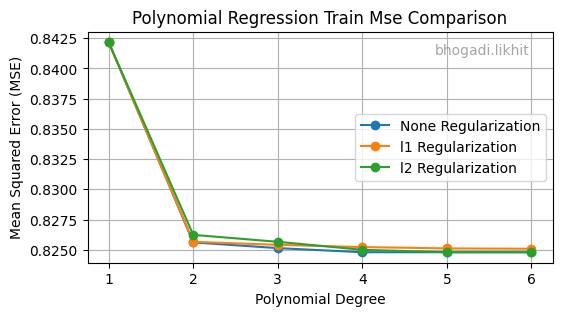

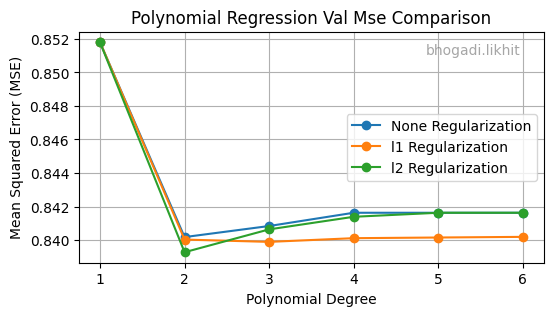

   regularizer  degree  best_strength  train_mse   val_mse
0         None       1            NaN   0.842172  0.851788
1         None       2            NaN   0.825613  0.840180
2         None       3            NaN   0.825139  0.840840
3         None       4            NaN   0.824799  0.841630
4         None       5            NaN   0.824799  0.841630
5         None       6            NaN   0.824799  0.841630
6           l1       1       0.000100   0.842172  0.851799
7           l1       2       0.000428   0.825658  0.840031
8           l1       3       0.000886   0.825409  0.839894
9           l1       4       0.000886   0.825224  0.840115
10          l1       5       0.000886   0.825115  0.840154
11          l1       6       0.000886   0.825087  0.840193
12          l2       1       0.000100   0.842172  0.851788
13          l2       2      48.329302   0.826235  0.839277
14          l2       3     100.000000   0.825661  0.840640
15          l2       4      48.329302   0.824998  0.8413

In [7]:
# Plot comparing different regularization types on the same graph

def plot_regularization_comparision(results):
    results_df = pd.DataFrame(results)
    for dataset in ['train_mse', 'val_mse']:
        plt.figure(figsize=(6, 3))
        for regularizer in ['None', 'l1', 'l2']:
            subset = results_df[results_df['regularizer'] == regularizer]
            plt.plot(subset['degree'], subset[dataset], marker='o', label=f'{regularizer} Regularization')
        
        plt.xlabel('Polynomial Degree')
        plt.ylabel('Mean Squared Error (MSE)')
        plt.title(f'Polynomial Regression {dataset.replace("_", " ").title()} Comparison')
        plt.xticks(range(1, 7))
        plt.legend()
        plt.grid(True)
        add_username_to_plot(USERNAME)
        
        # 1. Find the maximum MSE value in the current dataset's data
        max_mse = results_df[dataset].max()
        
        # 2. Set the top of the y-axis to be 20% higher than the max value
        top_limit = max_mse * 1.2
        
        # 3. Set both the bottom and top limits in one command
        # plt.ylim(bottom=0, top=top_limit)

        plt.show()
# Plot the regularization comparison
plot_regularization_comparision(results)
# Print the results in a tabular format for clarity
results_df = pd.DataFrame(results).drop(columns=['test_mse'])
print(results_df)

#### Trend observed as degree increases:

* The MSE for degrees 1 through 6 does not change much
* But we can observe a slight trend that MSE is a little higher for degree=1 and almost the same for degrees 2 through 6
* This is the case for both `val_mse` and `train_mse`
* Also no significant decrease in either of `val_mse` and `train_mse` with l1 and l2 regularizations

#### Finding best degree for each regularization

In [8]:
# Finding best degree for each regularization type based on validation MSE
def find_best_degrees(results):
    results_df = pd.DataFrame(results)
    best_degrees = {}
    
    for regularizer in ['None', 'l1', 'l2']:
        subset = results_df[results_df['regularizer'] == regularizer]
        best_row = subset.loc[subset['val_mse'].idxmin()]
        best_degrees[regularizer] = {
            'degree': best_row['degree'],
            'val_mse': best_row['val_mse'],
            'train_mse': best_row['train_mse'],
            'test_mse': best_row['test_mse'],
            'best_strength': best_row['best_strength']
        }
    
    return best_degrees
# Get the best degrees
best_degrees = find_best_degrees(results)
print("Best Degrees based on Validation MSE:")
for reg, info in best_degrees.items():
    print(f"Regularizer: {reg}, Best Degree: {info['degree']}, Val MSE: {info['val_mse']:.4f}, Train MSE: {info['train_mse']:.4f}, Test MSE: {info['test_mse']:.4f}, Best Strength: {info['best_strength']}")

Best Degrees based on Validation MSE:
Regularizer: None, Best Degree: 2, Val MSE: 0.8402, Train MSE: 0.8256, Test MSE: 0.8699, Best Strength: nan
Regularizer: l1, Best Degree: 3, Val MSE: 0.8399, Train MSE: 0.8254, Test MSE: 0.8696, Best Strength: 0.0008858667904100823
Regularizer: l2, Best Degree: 2, Val MSE: 0.8393, Train MSE: 0.8262, Test MSE: 0.8721, Best Strength: 48.32930238571752


#### Plots for regularization strength (log scale) vs val MSE

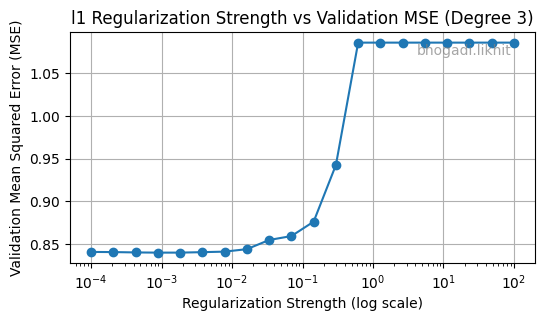

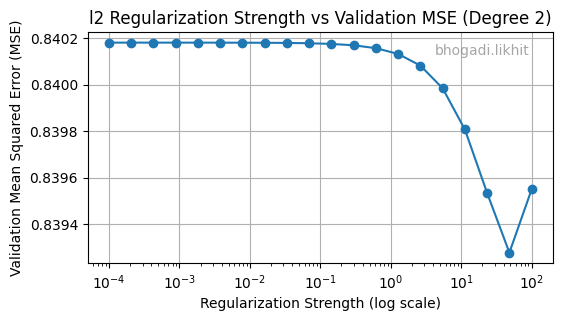

    regularizer  degree    strength   val_mse
0            l1       1    0.000100  0.851799
1            l1       1    0.000207  0.851811
2            l1       1    0.000428  0.851837
3            l1       1    0.000886  0.851892
4            l1       1    0.001833  0.852012
..          ...     ...         ...       ...
235          l2       6    5.455595  0.841686
236          l2       6   11.288379  0.841744
237          l2       6   23.357215  0.841851
238          l2       6   48.329302  0.842019
239          l2       6  100.000000  0.842234

[240 rows x 4 columns]


In [9]:
# plot regularization strength (log scale) vs val MSE for best degree

def plot_strength_vs_val_mse(strengths_results, best_degrees):
    strengths_df = pd.DataFrame(strengths_results)
    for regularizer in ['l1', 'l2']:
        best_degree = best_degrees[regularizer]['degree']
        subset = strengths_df[(strengths_df['regularizer'] == regularizer) & (strengths_df['degree'] == best_degree)]
        
        plt.figure(figsize=(6, 3))
        plt.semilogx(subset['strength'], subset['val_mse'], marker='o')
        
        plt.xlabel('Regularization Strength (log scale)')
        plt.ylabel('Validation Mean Squared Error (MSE)')
        plt.title(f'{regularizer} Regularization Strength vs Validation MSE (Degree {best_degree})')
        plt.grid(True)
        add_username_to_plot(USERNAME)
        
        # 1. Find the maximum MSE value in the current subset's data
        max_mse = subset['val_mse'].max()
        
        # 2. Set the top of the y-axis to be 20% higher than the max value
        top_limit = max_mse * 1.2
        
        # 3. Set both the bottom and top limits in one command
        # plt.ylim(bottom=0, top=top_limit)

        plt.show()
# Plot the strength vs validation MSE
plot_strength_vs_val_mse(strengths_results, best_degrees)
# Print the strengths results in a tabular format for clarity
strengths_df = pd.DataFrame(strengths_results)
print(strengths_df)
# Save the results to CSV files for future reference
results_df.to_csv('regression_results.csv', index=False)
strengths_df.to_csv('strengths_results.csv', index=False)

#### Comment on performance improvement (if any) from regularization

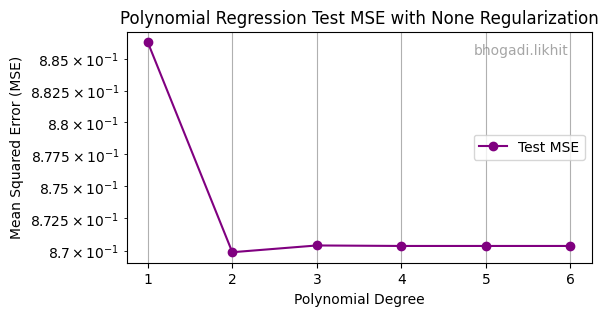

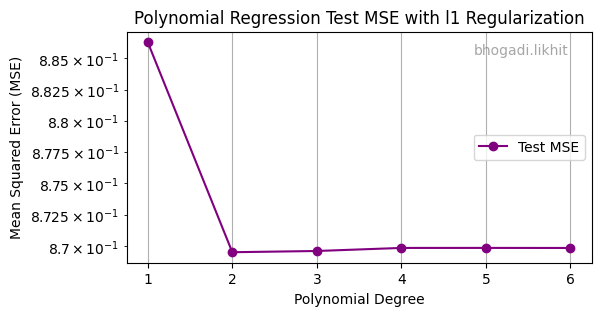

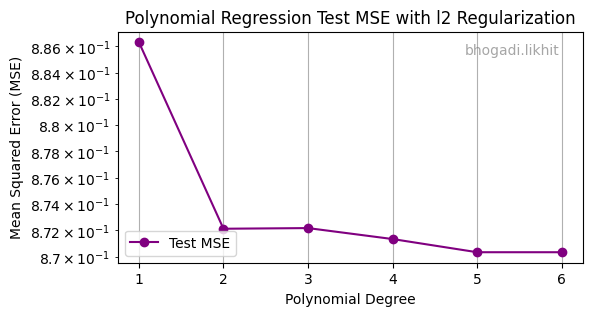

   regularizer  degree  best_strength  test_mse
0         None       1            NaN  0.886325
1         None       2            NaN  0.869872
2         None       3            NaN  0.870397
3         None       4            NaN  0.870358
4         None       5            NaN  0.870358
5         None       6            NaN  0.870358
6           l1       1       0.000100  0.886308
7           l1       2       0.000428  0.869540
8           l1       3       0.000886  0.869638
9           l1       4       0.000886  0.869880
10          l1       5       0.000886  0.869882
11          l1       6       0.000886  0.869876
12          l2       1       0.000100  0.886325
13          l2       2      48.329302  0.872129
14          l2       3     100.000000  0.872178
15          l2       4      48.329302  0.871352
16          l2       5       0.000100  0.870358
17          l2       6       0.000100  0.870358


In [10]:
# Plot Degree vs MSE for each regularization type for test set

def plot_test_results(results):
    """
    Plots Degree vs Test MSE for each regularization type.
    Parameters:
    - results: List of dictionaries containing results for each configuration.
    """
    # Convert results to DataFrame for easier plotting
    results_df = pd.DataFrame(results)
    for regularizer in ['None', 'l1', 'l2']:
        subset = results_df[results_df['regularizer'] == regularizer]
        
        plt.figure(figsize=(6, 3))
        plt.plot(subset['degree'], subset['test_mse'], marker='o', label='Test MSE', color='purple')
        
        plt.yscale('log')  # Use logarithmic scale for better visibility
        plt.xlabel('Polynomial Degree')
        plt.ylabel('Mean Squared Error (MSE)')
        plt.title(f'Polynomial Regression Test MSE with {regularizer} Regularization')
        plt.xticks(subset['degree'])
        plt.legend()
        plt.grid(True)
        add_username_to_plot(USERNAME)
        plt.show()
# Plot the test results
plot_test_results(results)
# Print the test results in a tabular format for clarity
results_df = pd.DataFrame(results).drop(columns=['train_mse', 'val_mse'])
print(results_df)

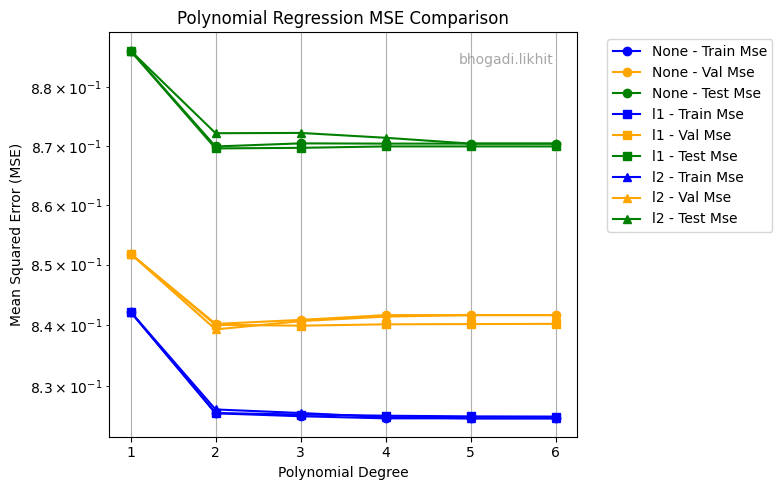

In [11]:
# plot all in one graph
def mse_comparison_plot(results):
    results_df = pd.DataFrame(results)
    plt.figure(figsize=(8, 5))
    
    markers = {'None': 'o', 'l1': 's', 'l2': '^'}
    colors = {'train_mse': 'blue', 'val_mse': 'orange', 'test_mse': 'green'}
    
    for regularizer in ['None', 'l1', 'l2']:
        subset = results_df[results_df['regularizer'] == regularizer]
        for dataset in ['train_mse', 'val_mse', 'test_mse']:
            plt.plot(subset['degree'], subset[dataset], marker=markers[regularizer], color=colors[dataset], 
                     label=f'{regularizer} - {dataset.replace("_", " ").title()}')
    
    plt.yscale('log')  # Use logarithmic scale for better visibility
    plt.xlabel('Polynomial Degree')
    plt.ylabel('Mean Squared Error (MSE)')
    plt.title('Polynomial Regression MSE Comparison')
    plt.xticks(range(1, 7))
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Place legend outside the plot
    plt.grid(True)
    add_username_to_plot(USERNAME)
    
    # 1. Find the maximum MSE value in the current dataset's data
    max_mse = results_df[['train_mse', 'val_mse', 'test_mse']].max().max()
    
    # 2. Set the top of the y-axis to be 20% higher than the max value
    top_limit = max_mse * 1.2
    
    # 3. Set both the bottom and top limits in one command
    # plt.ylim(bottom=0, top=top_limit)

    plt.tight_layout()  # Adjust layout to make room for legend
    plt.show()

# Plot the combined MSE comparison
mse_comparison_plot(results)

##### Comments:

* Based on above graphs and results, there is negligible performance difference among the 3 types of regularizations(None, L1, and L2)

#### Which overall experimental setup (degree, regularizer) yielded the best test performance?

In [12]:
# sort the performace (degree, regularizer) based on test MSE

sorted_results = sorted(results, key=lambda x: x['test_mse'])
print("Sorted Results based on Test MSE:")
for res in sorted_results:
    print(f"Regularizer: {res['regularizer']}, Degree: {res['degree']}, Test MSE: {res['test_mse']:.4f}, Train MSE: {res['train_mse']:.4f}, Val MSE: {res['val_mse']:.4f}, Best Strength: {res['best_strength']}")
# Save the sorted results to a CSV file
sorted_df = pd.DataFrame(sorted_results)
sorted_df.to_csv('sorted_regression_results.csv', index=False)

Sorted Results based on Test MSE:
Regularizer: l1, Degree: 2, Test MSE: 0.8695, Train MSE: 0.8257, Val MSE: 0.8400, Best Strength: 0.00042813323987193956
Regularizer: l1, Degree: 3, Test MSE: 0.8696, Train MSE: 0.8254, Val MSE: 0.8399, Best Strength: 0.0008858667904100823
Regularizer: None, Degree: 2, Test MSE: 0.8699, Train MSE: 0.8256, Val MSE: 0.8402, Best Strength: None
Regularizer: l1, Degree: 6, Test MSE: 0.8699, Train MSE: 0.8251, Val MSE: 0.8402, Best Strength: 0.0008858667904100823
Regularizer: l1, Degree: 4, Test MSE: 0.8699, Train MSE: 0.8252, Val MSE: 0.8401, Best Strength: 0.0008858667904100823
Regularizer: l1, Degree: 5, Test MSE: 0.8699, Train MSE: 0.8251, Val MSE: 0.8402, Best Strength: 0.0008858667904100823
Regularizer: None, Degree: 5, Test MSE: 0.8704, Train MSE: 0.8248, Val MSE: 0.8416, Best Strength: None
Regularizer: None, Degree: 4, Test MSE: 0.8704, Train MSE: 0.8248, Val MSE: 0.8416, Best Strength: None
Regularizer: None, Degree: 6, Test MSE: 0.8704, Train MSE:

* Best test performance is by L1, Degree=2, with Test MSE = 0.8695

### Step 5: Feature Importance

##### For the best setup using L1 regularization, which features had non-zero weights?

In [16]:
# --- Section 1: All Necessary Imports & Helper Functions ---
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import Pipeline

# --- Section 3: Build and Train the Specified Best Models ---

# From your analysis, the best parameters are known:
BEST_DEGREE_L1 = 2
BEST_DEGREE_L2 = 2 # Assuming a similar best degree for Ridge for comparison

# 1. Build and train the best L1 (Lasso) model
print(f"\nTraining best L1 model with degree={BEST_DEGREE_L1}...")
best_l1_pipeline = build_regression_pipeline(degree=BEST_DEGREE_L1, regularizer='l1')
best_l1_pipeline.fit(X_train, y_train)

# 2. Build and train the best L2 (Ridge) model for comparison
print(f"Training best L2 model with degree={BEST_DEGREE_L2}...")
best_l2_pipeline = build_regression_pipeline(degree=BEST_DEGREE_L2, regularizer='l2')
best_l2_pipeline.fit(X_train, y_train)


# --- Section 4: Feature Importance Analysis ---

# Get the feature names AFTER the PolynomialFeatures transformation
poly_features_l1 = best_l1_pipeline.named_steps['poly_features']
feature_names_l1 = poly_features_l1.get_feature_names_out(input_features=X_train.columns)

poly_features_l2 = best_l2_pipeline.named_steps['poly_features']
feature_names_l2 = poly_features_l2.get_feature_names_out(input_features=X_train.columns)

print("\n" + "="*50)
print("           FEATURE IMPORTANCE ANALYSIS")
print("="*50)

# 1. Analyze L1 (Lasso) Model Coefficients
print("\n--- L1 (Lasso) Model: Feature Importance ---")
l1_coefs = best_l1_pipeline.named_steps['model'].coef_
l1_importance = pd.Series(l1_coefs, index=feature_names_l1)
l1_important_features = l1_importance[l1_importance != 0].sort_values(ascending=False)

if l1_important_features.empty:
    print("Lasso model eliminated all features (all coefficients are zero).")
else:
    print("Features with non-zero coefficients (selected by Lasso):")
    print(l1_important_features)

# 2. Analyze L2 (Ridge) Model Coefficients
print("\n--- L2 (Ridge) Model: Feature Importance ---")
l2_coefs = best_l2_pipeline.named_steps['model'].coef_
l2_importance = pd.Series(l2_coefs, index=feature_names_l2)
# For Ridge, find the top 10 features with the largest absolute values
l2_top_features = l2_importance.abs().sort_values(ascending=False).head(10)

print("Top 10 most important features (by absolute coefficient value):")
# Display the actual coefficients for these top features
print(l2_importance.loc[l2_top_features.index])

print("\n✅ Feature importance analysis finished.")


Training best L1 model with degree=2...
Training best L2 model with degree=2...

           FEATURE IMPORTANCE ANALYSIS

--- L1 (Lasso) Model: Feature Importance ---
Features with non-zero coefficients (selected by Lasso):
Major                       0.635034
Major Gender_Male           0.008430
Major Program_CSE           0.004583
Gender_Other Program_ECE    0.001183
Program_CSE^2              -0.009605
Major^2                    -0.178671
dtype: float64

--- L2 (Ridge) Model: Feature Importance ---
Top 10 most important features (by absolute coefficient value):
Major                       0.831088
Major^2                    -0.405401
Gender_Other Program_ECE    0.022952
Major Gender_Male           0.022825
Major Program_CSE           0.022064
Program_CSE                -0.021935
Program_CSE^2              -0.021935
Gender_Male Program_CND    -0.018043
Gender_Other Program_CSE    0.017999
Program_ECE                -0.016013
dtype: float64

✅ Feature importance analysis finished.


##### Analysis of Feature Importance: L1 (Lasso) vs. L2 (Ridge)

* Key Findings

Both models agree that a student's **`Major`** is the single most important predictor. However, they use fundamentally different strategies to handle other features.

---

* L1 (Lasso) Model Analysis

Lasso performs **feature selection**, creating a sparse and simple model.

-   **Action:** It forced the coefficients of most features to become **exactly zero**, effectively removing them.
-   **Result:** The final model uses only **6 key features** to make its prediction.
-   **Most Important Features:**
    1.  `Major` (Large positive impact)
    2.  `Major^2` (Large negative impact, suggesting a non-linear relationship)
    3.  Minor interaction terms (e.g., `Major Gender_Male`)

---

* L2 (Ridge) Model Analysis

Ridge performs **coefficient shrinkage**, creating a more complex model where all features contribute.

-   **Action:** It reduced the magnitude of less important features, shrinking them closer to zero but not eliminating them entirely.
-   **Result:** The model retains **all features**, but weighs them differently.
-   **Most Important Features:**
    1.  `Major` (Large positive impact)
    2.  `Major^2` (Large negative impact)
    3.  Various interaction terms with smaller, moderated impacts.

---

* Comparison and Conclusion

| Aspect              | L1 (Lasso) Model          | L2 (Ridge) Model             |
| ------------------- | ------------------------- | ---------------------------- |
| **Strategy** | Feature Selection         | Coefficient Shrinkage        |
| **Model Complexity**| **Simple** (Sparse)       | **Complex** (Dense)          |
| **Result** | Selects the few "best" features. | Keeps all features but reduces their impact. |

The primary difference is that **Lasso provides a simpler, more interpretable model** by aggressively eliminating features, while **Ridge offers a more stable model** by retaining all information and just moderating its influence. The strong agreement on `Major` as the top feature gives high confidence in its predictive power.